# PatchCore
Method from the literature (Roth et al., 2022), used for the comparison with the custom model.
No training: a frozen ImageNet-pretrained backbone extracts patch features from the normal training images, and a
coreset (10%) of them is kept as memory bank. At test time the anomaly map is the distance of each patch from its
nearest neighbor in the memory bank (smoothed with sigma 4); the image score is the maximum patch distance,
re-weighted with its 9 nearest neighbors.

Same protocol as the custom model: same split (fit on `train/`), 256x256 images, same `evaluate`.
Model from anomalib (`PatchcoreModel`), wrapped in `models/literature_models.py`; runs in `run_literature.py`.
Backbone `resnet18.tv_in1k`: the torchvision weights, the same as the teacher of the custom model.
The main image score is the native one (`image_auroc`); `image_auroc_top1pct` uses the top-1% score of the custom model.

In [3]:
from run_literature import run_literature_single_class, build_literature_model
from run_experiment import build_dataloaders
from utils.visualization import visualize_anomalies
from utils.helpers import get_device
from pathlib import Path
import pandas as pd

from warnings import filterwarnings
filterwarnings("ignore")

In [ ]:
config = {

    'experiment_name': 'resnet18',

    'device': 'cuda',
    'num_workers': 0,
    'seed': 42,

    # dataset
    'img_size': (256, 256),
    'batch_size': 32,

    # model (default values of anomalib)
    'model_name': 'PatchCore',
    'backbone_name': 'resnet18.tv_in1k',
    'feature_layers': ['layer2', 'layer3'],
    'coreset_sampling_ratio': 0.1,
    'num_neighbors': 9,
    'output_dir': './experiments/patchcore',
}

DEVICE = get_device(config['device'])

In [3]:
classes_to_run = ['bottle', 'cable', 'capsule', 'carpet', 'grid', 'hazelnut', 'leather', 'metal_nut', 'pill', 'screw', 'tile', 'toothbrush', 'transistor', 'wood', 'zipper']
all_results = {}

for cls in classes_to_run:
    all_results[cls] = run_literature_single_class(cls, config)

df_results = pd.DataFrame.from_dict(all_results, orient='index')
df_results.loc['MEAN'] = df_results.mean()

results_csv = Path(config['output_dir']) / config['experiment_name'] / "overall_results.csv"
df_results.to_csv(results_csv)

display(df_results.round(4))


==============================  Starting class: BOTTLE  ==============================
Random seed set to 42.


Evaluating: 100%|██████████| 3/3 [00:02<00:00,  1.27it/s]



==============================  Starting class: CABLE  ==============================
Random seed set to 42.


Evaluating: 100%|██████████| 5/5 [00:07<00:00,  1.45s/it]



==============================  Starting class: CAPSULE  ==============================
Random seed set to 42.


Evaluating: 100%|██████████| 5/5 [00:05<00:00,  1.12s/it]


... (21 outputs left out)

Evaluating: 100%|██████████| 3/3 [00:03<00:00,  1.23s/it]



==============================  Starting class: ZIPPER  ==============================
Random seed set to 42.


Evaluating: 100%|██████████| 5/5 [00:04<00:00,  1.18it/s]


,image_auroc,pixel_auroc,aupro,image_auroc_top1pct
bottle,1.0000,0.9831,0.9337,1.0000
cable,0.9792,0.9852,0.9384,0.9948
capsule,0.9832,0.9887,0.9244,0.9813
carpet,0.9843,0.9896,0.9504,0.9791
grid,0.9724,0.9756,0.9100,0.9607
hazelnut,0.9989,0.9869,0.9438,0.9996
leather,1.0000,0.9922,0.9743,1.0000
metal_nut,0.9980,0.9835,0.9439,0.9971
pill,0.9381,0.9757,0.9363,0.9362
screw,0.9471,0.9930,0.9681,0.9553


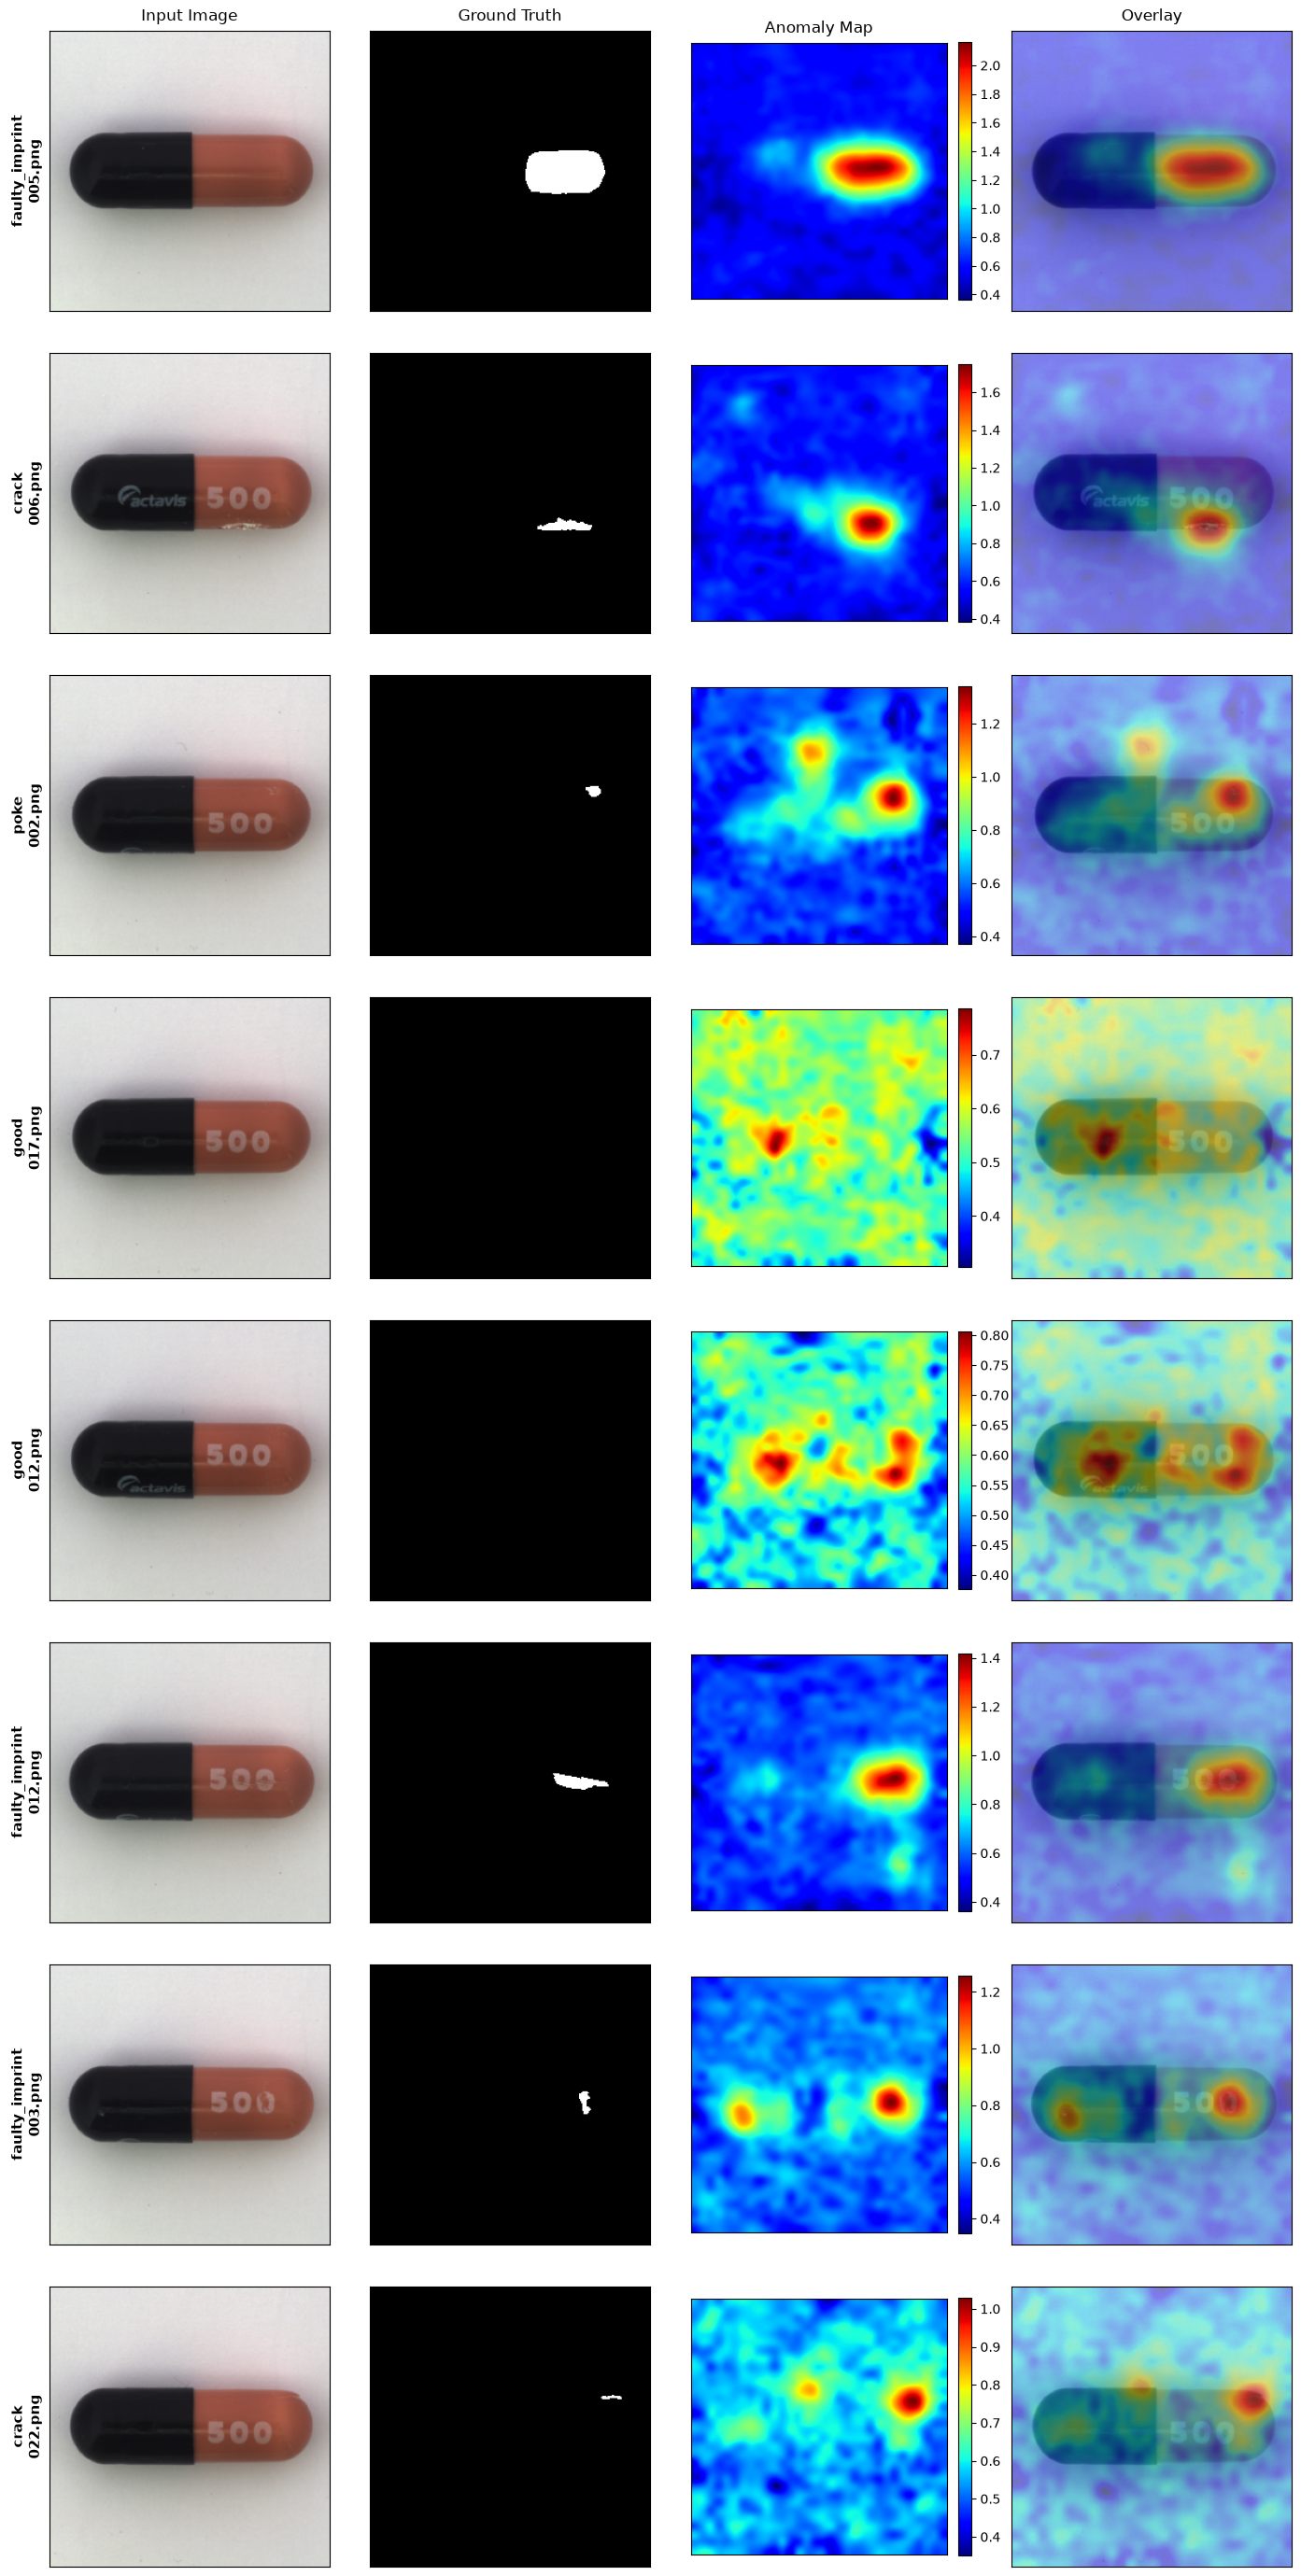

In [ ]:
object_name = "capsule" 
memory_bank_path = Path(config['output_dir']) / config['experiment_name'] / object_name / "memory_bank.pt"

_, _, test_loader = build_dataloaders(object_name, config)
model = build_literature_model(config, DEVICE, memory_bank_path=memory_bank_path)
visualize_anomalies(model, test_loader, DEVICE)

## Results and conclusions
Mean over the 15 classes, compared with the final custom model.
Selection metric computed as (Image AUROC + AUPRO) / 2, as for the ablations of the custom model.

| model | Image AUROC (native) | Image AUROC (top-1%) | Pixel AUROC | AUPRO | selection |
|---|---|---|---|---|---|
| **PatchCore** | **0.978** | **0.982** | **0.978** | **0.928** | **0.953** |
| custom model | 0.962 | 0.962 | 0.962 | 0.899 | 0.931 |

- PatchCore is better than the custom model on every metric, with the same backbone
  and the same training images. The largest gap is in localization (AUPRO).
- Per class, PatchCore is weakest on tile (AUPRO 0.831), toothbrush, pill and wood, and close to perfect on leather,
  hazelnut, metal_nut and bottle.
- The native score and the top-1% score of the map give almost the same result. The only clear
  difference is on toothbrush.

The per-class comparison with the custom model and PaDiM, and the analysis of the errors, are in `error_analysis.ipynb`.